In [1]:
import requests
import pandas as pd
from datetime import datetime, timezone

# Mandatory parameters
SYMBOL = "ETHUSDT"
#SYMBOL = "BTCUSDT"
endpoint = "https://api.binance.com/api/v3/klines"

# 1 Jan 2023 00:00 UTC 
start = datetime(2023, 1, 1, tzinfo=timezone.utc)

# 22 Sep 2026 00:00 UTC
end = datetime(2026, 9, 22, tzinfo=timezone.utc)

start_ms = int(start.timestamp() * 1000)
end_ms = int(end.timestamp() * 1000)

rows = []
cursor = start_ms

while cursor < end_ms:
    response = requests.get(
        endpoint,
        params={
            "symbol": SYMBOL,
            "interval": "1h",
            "startTime": cursor,
            "endTime": end_ms - 1,
            "limit": 1000,
        },
        timeout=30,
    )
    response.raise_for_status()
    batch = response.json()

    if not batch:
        break

    rows.extend(batch)
    cursor = int(batch[-1][0]) + 60 * 60 * 1000

    if len(batch) < 1000:
        break

columns = [
    "open_time", "open", "high", "low", "close", "volume",
    "close_time", "quote_volume", "trades",
    "taker_buy_volume", "taker_buy_quote_volume", "ignore",
]

bars = pd.DataFrame(rows, columns=columns)

if bars.empty:
    raise RuntimeError("Binance does not return any data")

bars["open_time"] = pd.to_datetime(bars["open_time"], unit="ms", utc=True)
bars["close_time"] = pd.to_datetime(bars["close_time"], unit="ms", utc=True)

numeric_columns = [
    "open", "high", "low", "close", "volume",
    "quote_volume", "taker_buy_volume", "taker_buy_quote_volume",
]

bars[numeric_columns] = bars[numeric_columns].astype(float)
bars = bars.drop_duplicates("open_time").sort_values("open_time").reset_index(drop=True)

print(f"Bars downloaded: {len(bars)}")
print(f"Period: {bars['open_time'].min()} — {bars['open_time'].max()}")

bars.head()

Bars downloaded: 32639
Period: 2023-01-01 00:00:00+00:00 — 2026-09-21 23:00:00+00:00


,open_time,open,high,low,close,volume,close_time,quote_volume,trades,taker_buy_volume,taker_buy_quote_volume,ignore
0,2023-01-01 00:00:00+00:00,1196.13,1196.70,1192.72,1194.09,5889.3840,2023-01-01 00:59:59.999000+00:00,7.036230e+06,15832,2550.8294,3.046972e+06,0
1,2023-01-01 01:00:00+00:00,1194.09,1196.37,1193.84,1196.02,3157.2079,2023-01-01 01:59:59.999000+00:00,3.773475e+06,8245,1583.8715,1.892940e+06,0
2,2023-01-01 02:00:00+00:00,1196.01,1196.74,1194.11,1195.40,3752.0476,2023-01-01 02:59:59.999000+00:00,4.484632e+06,8377,1771.7331,2.117552e+06,0
3,2023-01-01 03:00:00+00:00,1195.41,1195.41,1191.71,1194.04,7493.4207,2023-01-01 03:59:59.999000+00:00,8.941607e+06,10244,3409.5492,4.068126e+06,0
4,2023-01-01 04:00:00+00:00,1194.05,1194.05,1190.57,1192.92,6409.2491,2023-01-01 04:59:59.999000+00:00,7.641847e+06,10211,2832.3239,3.377225e+06,0


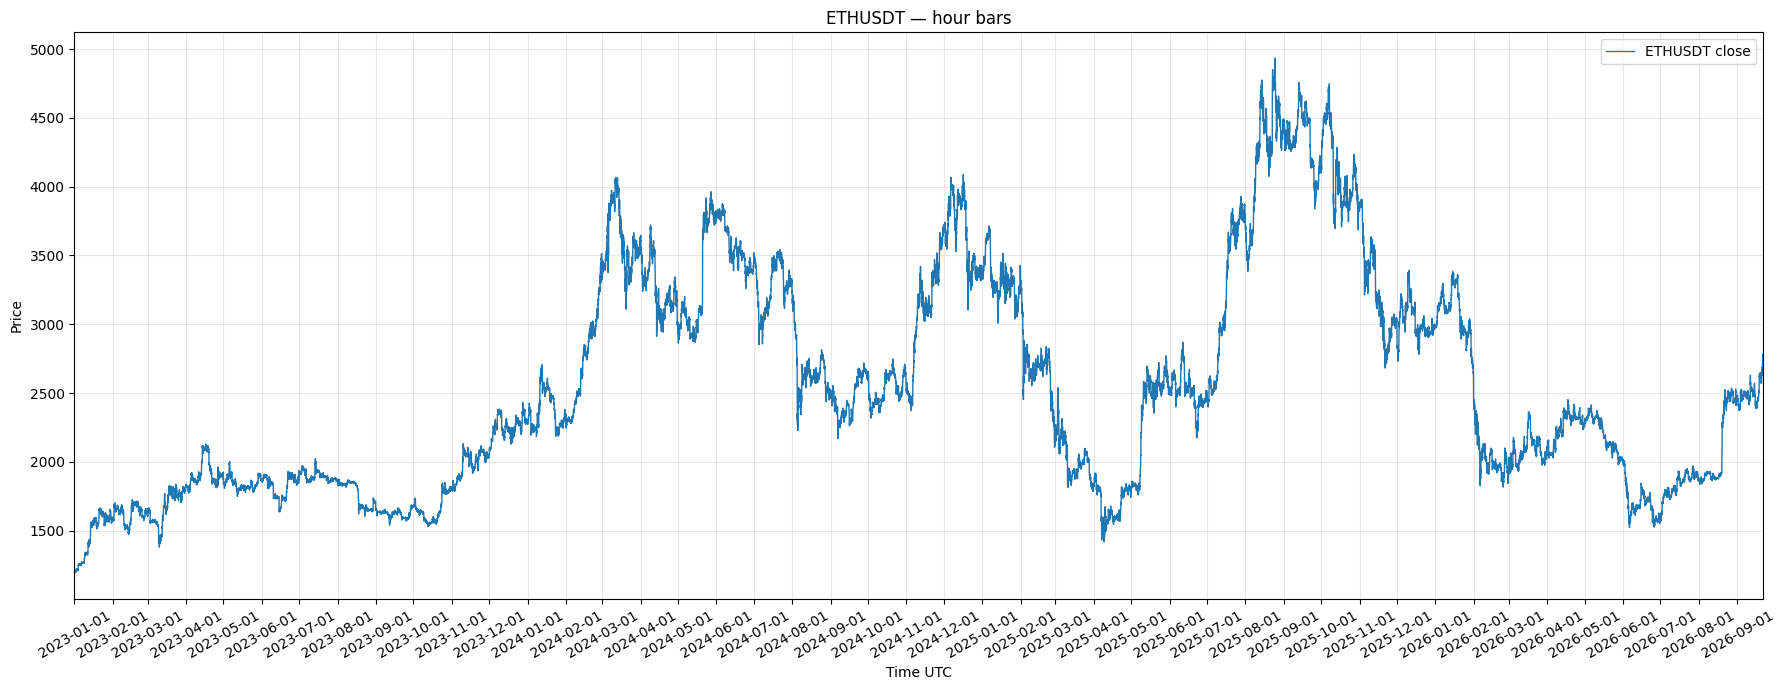

In [2]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

if "bars" not in globals() or bars.empty:
    raise RuntimeError("No bar data")

fig, ax = plt.subplots(figsize=(18, 7))

ax.plot(
    bars["open_time"],
    bars["close"],
    linewidth=1,
    label=f"{SYMBOL} close"
)

# Exact X-axis boundaries — no empty space
ax.set_xlim(
    bars["open_time"].min(),
    bars["open_time"].max()
)

ax.set_title(f"{SYMBOL} — hour bars")
ax.set_xlabel("Time UTC")
ax.set_ylabel("Price")
ax.grid(True, alpha=0.3)
ax.legend()

ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%Y-%m-%d", tz=bars["open_time"].dt.tz)
)

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [3]:

import numpy as np
import pandas as pd

# ==========================================
# RETROSPECTIVELY SELECTED LP RANGE
# ==========================================

DAYS = 600
HOURS = DAYS * 24

LOWER = 1500.0
UPPER = 4000.0

# Prepare historical dataset
data = (
    bars.copy()
    .sort_values("open_time")
    .drop_duplicates("open_time")
    .set_index("open_time")
)

# Last available hourly candle
AS_OF = data.index.max()

# Exactly 600 days before observation
ENTRY_DATE = AS_OF - pd.Timedelta(days=DAYS)

# Include both endpoints: 14,401 observations
history = data.loc[ENTRY_DATE:AS_OF].copy()

if len(history) != HOURS + 1:
    raise RuntimeError(
        f"Expected {HOURS + 1} bars, got {len(history)}"
    )

if not (
    history.index.to_series().diff().dropna()
    == pd.Timedelta(hours=1)
).all():
    raise RuntimeError("Missing or irregular hourly candles")

ENTRY_PRICE = float(history["close"].iloc[0])

# ==========================================
# HISTORICAL EXTREMES
# ==========================================

HIST_LOWER = float(history["low"].min())
HIST_UPPER = float(history["high"].max())

# ==========================================
# LP RANGE PARAMETERS
# ==========================================

WIDTH = (UPPER - LOWER) / ENTRY_PRICE

LOWER_DISTANCE = (
    (ENTRY_PRICE - LOWER) / ENTRY_PRICE * 100
)

UPPER_DISTANCE = (
    (UPPER - ENTRY_PRICE) / ENTRY_PRICE * 100
)

# ==========================================
# RANGE OCCUPANCY
# ==========================================

in_range = (
    (history["close"] >= LOWER) &
    (history["close"] <= UPPER)
)

TIME_IN_RANGE = in_range.mean() * 100

fully_inside = (
    (history["low"] >= LOWER) &
    (history["high"] <= UPPER)
)

FULLY_INSIDE = fully_inside.mean() * 100

hours_above = int((history["close"] > UPPER).sum())
hours_below = int((history["close"] < LOWER).sum())

# Candle touches / crosses LP boundaries
candles_outside = int((~fully_inside).sum())

# ==========================================
# RESULTS
# ==========================================

print("RETROSPECTIVELY SELECTED LP RANGE")
print("-" * 50)

print(f"Entry date:        {ENTRY_DATE}")
print(f"Observation date:  {AS_OF}")
print(f"Entry price:       ${ENTRY_PRICE:,.2f}")
print(f"Age:               {DAYS} days")
print(f"Hourly intervals:  {HOURS:,}")
print(f"Price observations:{len(history):,}")

print("\nLP RANGE")
print(f"Lower bound:       ${LOWER:,.2f}")
print(f"Upper bound:       ${UPPER:,.2f}")
print(f"Relative width:    {WIDTH:.2%}")
print(f"Distance to lower: {LOWER_DISTANCE:+.2f}%")
print(f"Distance to upper: {UPPER_DISTANCE:+.2f}%")

print("\nHISTORICAL PRICE EXTREMES")
print(f"Historical low:    ${HIST_LOWER:,.2f}")
print(f"Historical high:   ${HIST_UPPER:,.2f}")

print("\nRANGE OCCUPANCY")
print(f"Closes in range:   {TIME_IN_RANGE:.2f}%")
print(f"Fully inside:      {FULLY_INSIDE:.2f}%")
print(f"Closes above:      {hours_above:,}")
print(f"Closes below:      {hours_below:,}")
print(f"Candles crossing or outside: {candles_outside:,}")


RETROSPECTIVELY SELECTED LP RANGE
--------------------------------------------------
Entry date:        2025-01-29 23:00:00+00:00
Observation date:  2026-09-21 23:00:00+00:00
Entry price:       $3,113.90
Age:               600 days
Hourly intervals:  14,400
Price observations:14,401

LP RANGE
Lower bound:       $1,500.00
Upper bound:       $4,000.00
Relative width:    80.29%
Distance to lower: +51.83%
Distance to upper: +28.46%

HISTORICAL PRICE EXTREMES
Historical low:    $1,385.05
Historical high:   $4,956.78

RANGE OCCUPANCY
Closes in range:   88.39%
Fully inside:      88.03%
Closes above:      1,641
Closes below:      31
Candles crossing or outside: 1,724


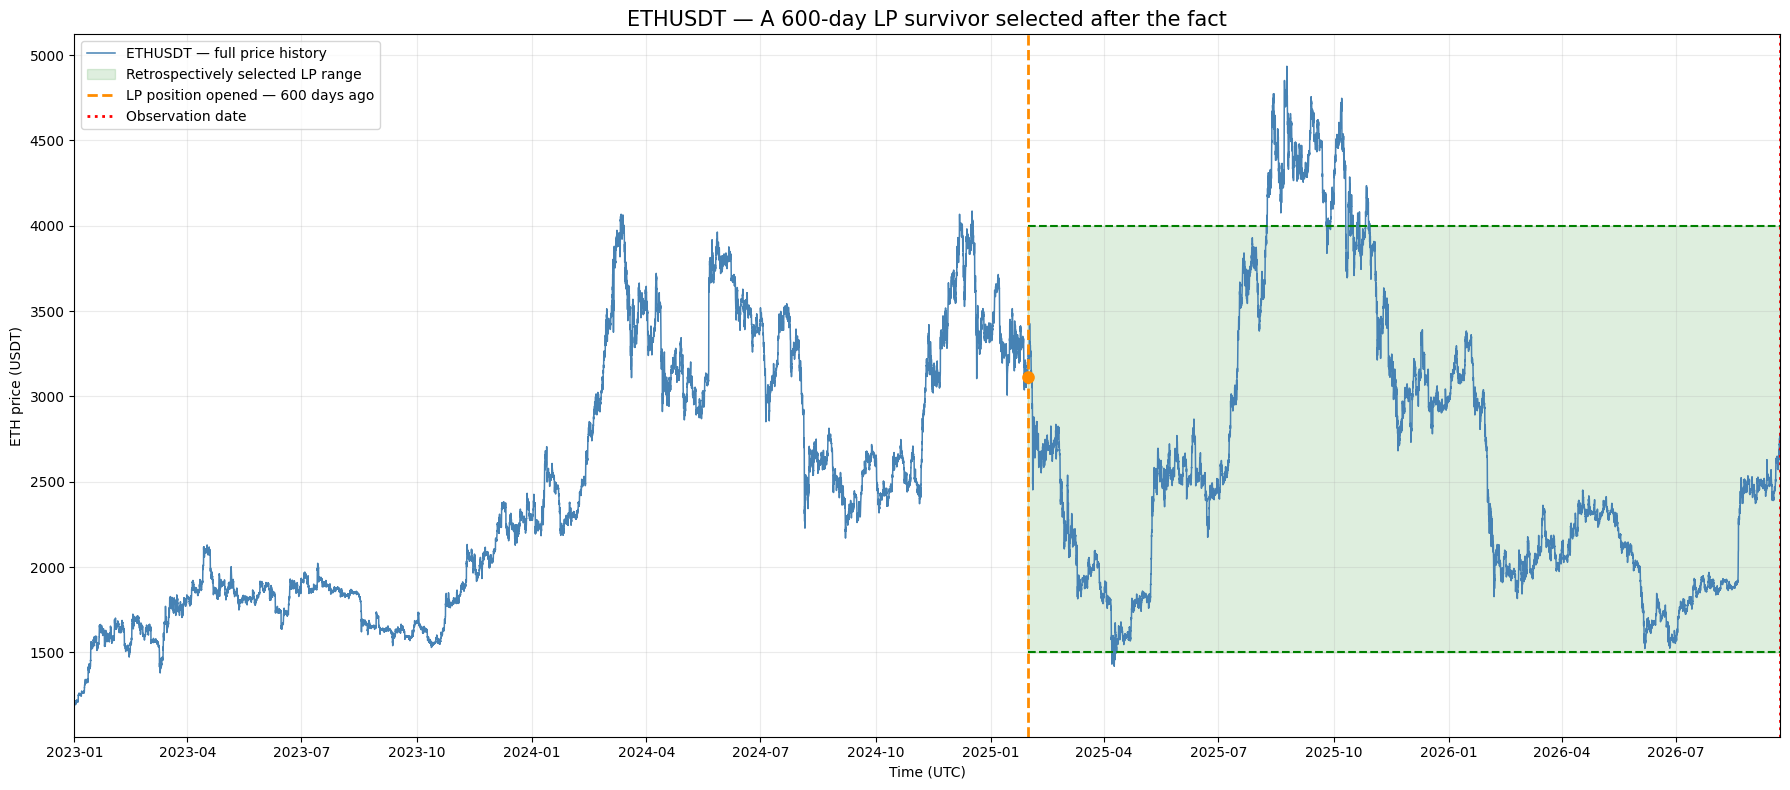

In [4]:

import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# ==========================================
# HISTORICAL LP SURVIVOR — FULL PRICE HISTORY
# ==========================================

fig, ax = plt.subplots(figsize=(18, 8))

# Full historical ETH price
ax.plot(
    data.index,
    data["close"],
    color="steelblue",
    linewidth=1.1,
    label="ETHUSDT — full price history"
)

# LP range visible only during position lifetime
ax.fill_between(
    history.index,
    LOWER,
    UPPER,
    color="green",
    alpha=0.13,
    label="Retrospectively selected LP range"
)

# Range boundaries from hypothetical entry onward
ax.hlines(
    [LOWER, UPPER],
    xmin=ENTRY_DATE,
    xmax=AS_OF,
    colors="green",
    linestyles="--",
    linewidth=1.5
)

# Hypothetical position opening date
ax.axvline(
    ENTRY_DATE,
    color="darkorange",
    linestyle="--",
    linewidth=2,
    label="LP position opened — 600 days ago"
)

ax.scatter(
    ENTRY_DATE,
    ENTRY_PRICE,
    color="darkorange",
    s=65,
    zorder=5
)

# Observation date
ax.axvline(
    AS_OF,
    color="red",
    linestyle=":",
    linewidth=2,
    label="Observation date"
)

ax.set_title(
    "ETHUSDT — A 600-day LP survivor selected after the fact",
    fontsize=15
)

ax.set_xlabel("Time (UTC)")
ax.set_ylabel("ETH price (USDT)")

ax.set_xlim(
    data.index.min(),
    AS_OF
)

ax.grid(alpha=0.25)
ax.legend(loc="upper left")

ax.xaxis.set_major_locator(
    mdates.MonthLocator(interval=3)
)
ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%Y-%m", tz=timezone.utc)
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


Generated 10,000 paths with 24h blocks
Generated 10,000 paths with 168h blocks
Generated 10,000 paths with 720h blocks

VALIDATION PASSED
Period: 2025-01-29 23:00:00+00:00 to 2026-09-21 23:00:00+00:00
Hourly intervals: 14400
Price observations: 14401
Original start: $3,113.90
Original end: $2,776.19
Paths per block size: 10000
All terminal prices verified.


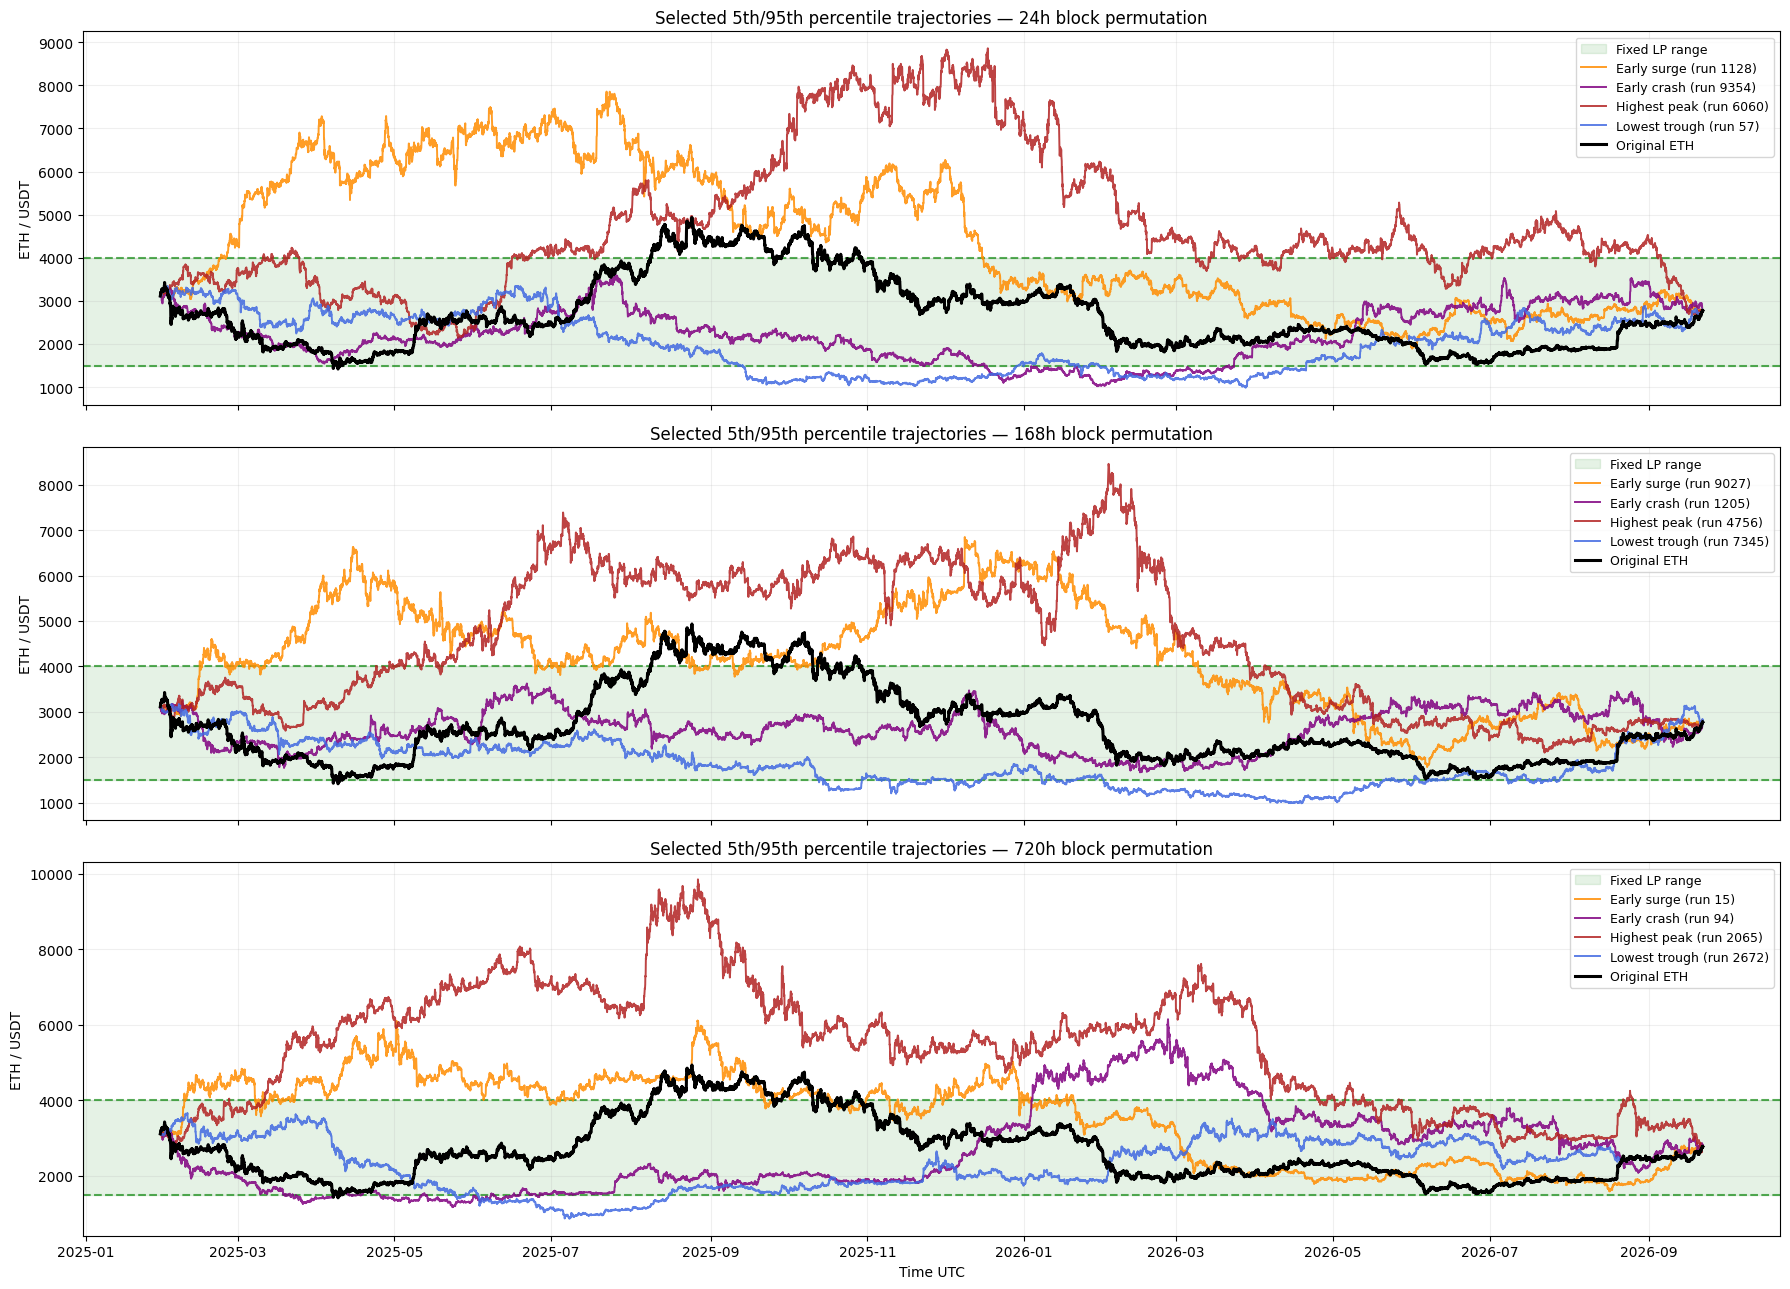


SELECTED PATH COMPARISON


,Block hours,Scenario,Run ID,First 30d max,First 30d min,Full max,Full min,Time in range (%)
0,24,Early surge,1128,4557.97,3041.28,7854.71,1891.07,50.71
1,24,Early crash,9354,3300.30,2135.26,3591.12,1020.04,83.79
2,24,Highest peak,6060,3848.64,3082.69,8859.50,2141.28,30.38
3,24,Lowest trough,57,3346.99,2930.12,3346.99,986.15,67.79
4,168,Early surge,9027,4601.65,2916.45,6847.08,1792.42,39.20
5,168,Early crash,1205,3242.55,2099.84,3624.91,1669.57,100.00
6,168,Highest peak,4756,3755.21,2810.29,8457.04,2106.75,44.77
7,168,Lowest trough,7345,3174.99,2408.88,3174.99,991.59,68.85
8,720,Early surge,15,4799.00,3015.24,6109.62,1589.36,52.12
9,720,Early crash,94,3205.11,1926.22,6147.52,1170.81,71.91


In [5]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==================================================
# EXPERIMENT: SAME RETURNS, DIFFERENT ORDER
# 600 DAYS = 14,400 RETURNS = 14,401 PRICES
# ==================================================

N_PATHS = 10_000
BLOCK_SIZES = [24, 168, 720]
SEED = 42

EARLY_DAYS = 30
EARLY_HOURS = EARLY_DAYS * 24

rng = np.random.default_rng(SEED)

# ==================================================
# 1. PREPARE HISTORICAL DATA
# ==================================================

# Reuse the already validated 600-day history.
times = history.index
original_path = history["close"].to_numpy(dtype=float)

if len(original_path) != HOURS + 1:
    raise RuntimeError(
        f"Expected {HOURS + 1} prices, got {len(original_path)}"
    )

if times[0] != ENTRY_DATE or times[-1] != AS_OF:
    raise RuntimeError("Historical time boundaries do not match")

if not (
    times.to_series().diff().dropna() == pd.Timedelta(hours=1)
).all():
    raise RuntimeError("Missing or irregular hourly candles")

if not np.all(np.isfinite(original_path)):
    raise ValueError("Non-finite prices detected")

if np.any(original_path <= 0):
    raise ValueError("Prices must be positive")

P0 = float(original_path[0])

# Exactly 14,400 hourly log returns
returns = np.diff(np.log(original_path))

assert len(returns) == HOURS

# ==================================================
# 2. BLOCK PERMUTATION FUNCTIONS
# ==================================================

def permute_blocks(returns, block_hours, rng):
    """
    Split observed log returns into consecutive blocks.
    Shuffle blocks without replacement.
    Preserve the order inside each block.
    """

    blocks = [
        returns[i:i + block_hours]
        for i in range(0, len(returns), block_hours)
    ]

    order = rng.permutation(len(blocks))

    return np.concatenate([
        blocks[i] for i in order
    ])


def reconstruct_path(start_price, log_returns):

    cumulative = np.concatenate([
        [0.0],
        np.cumsum(log_returns)
    ])

    return start_price * np.exp(cumulative)


def closest_percentile_index(values, percentile):

    target = np.percentile(values, percentile)

    return int(
        np.argmin(np.abs(values - target))
    )


# ==================================================
# 3. GENERATE PATHS AND CACHE PRICE STATISTICS
# ==================================================

simulations = {}
path_stats = {}

for block_size in BLOCK_SIZES:

    paths = np.empty(
        (N_PATHS, HOURS + 1),
        dtype=np.float64
    )

    for i in range(N_PATHS):

        shuffled = permute_blocks(
            returns,
            block_size,
            rng
        )

        paths[i] = reconstruct_path(
            P0,
            shuffled
        )

    simulations[block_size] = paths

    # Calculate price statistics once per simulation set
    path_stats[block_size] = {
        "early_max": paths[:, :EARLY_HOURS + 1].max(axis=1),
        "early_min": paths[:, :EARLY_HOURS + 1].min(axis=1),
        "full_max": paths.max(axis=1),
        "full_min": paths.min(axis=1),
        "mean_price": paths.mean(axis=1)
    }

    print(
        f"Generated {N_PATHS:,} paths "
        f"with {block_size}h blocks"
    )


# ==================================================
# 4. VALIDATION
# ==================================================

for block_size, paths in simulations.items():

    assert paths.shape == (N_PATHS, HOURS + 1)

    assert np.allclose(
        paths[:, 0],
        P0
    )

    assert np.allclose(
        paths[:, -1],
        original_path[-1],
        rtol=1e-10,
        atol=1e-8
    )

print("\nVALIDATION PASSED")
print("Period:", times[0], "to", times[-1])
print("Hourly intervals:", HOURS)
print("Price observations:", len(times))
print(f"Original start: ${P0:,.2f}")
print(f"Original end: ${original_path[-1]:,.2f}")
print("Paths per block size:", N_PATHS)
print("All terminal prices verified.")


# ==================================================
# 5. SELECT PATHS BY PERCENTILES
# ==================================================

selected_paths = {}

for block_size in BLOCK_SIZES:

    stats = path_stats[block_size]

    idx_early_surge = closest_percentile_index(
        stats["early_max"], 95
    )

    idx_early_crash = closest_percentile_index(
        stats["early_min"], 5
    )

    idx_highest = closest_percentile_index(
        stats["full_max"], 95
    )

    idx_lowest = closest_percentile_index(
        stats["full_min"], 5
    )

    selected_paths[block_size] = [
        ("Early surge", idx_early_surge, "darkorange"),
        ("Early crash", idx_early_crash, "purple"),
        ("Highest peak", idx_highest, "firebrick"),
        ("Lowest trough", idx_lowest, "royalblue")
    ]


# ==================================================
# 6. VISUALIZATION — SELECTED PRICE PATHS
# ==================================================

fig, axes = plt.subplots(
    len(BLOCK_SIZES), 1,
    figsize=(18, 13),
    sharex=True
)

for ax, block_size in zip(axes, BLOCK_SIZES):

    paths = simulations[block_size]
    selections = selected_paths[block_size]

    ax.axhspan(
        LOWER,
        UPPER,
        color="green",
        alpha=0.10,
        label="Fixed LP range"
    )

    ax.axhline(
        LOWER,
        color="green",
        linestyle="--",
        alpha=0.65
    )

    ax.axhline(
        UPPER,
        color="green",
        linestyle="--",
        alpha=0.65
    )

    for label, idx, color in selections:

        ax.plot(
            times,
            paths[idx],
            color=color,
            alpha=0.85,
            linewidth=1.4,
            label=f"{label} (run {idx})"
        )

    ax.plot(
        times,
        original_path,
        color="black",
        linewidth=2.2,
        label="Original ETH",
        zorder=10
    )

    ax.set_title(
        f"Selected 5th/95th percentile trajectories "
        f"— {block_size}h block permutation"
    )

    ax.set_ylabel("ETH / USDT")
    ax.grid(alpha=0.20)
    ax.legend(loc="upper right", fontsize=9)

axes[-1].set_xlabel("Time UTC")

plt.tight_layout()
plt.show()


# ==================================================
# 7. SELECTION STATISTICS
# ==================================================

records = []

for block_size, selections in selected_paths.items():

    paths = simulations[block_size]
    stats = path_stats[block_size]

    for label, idx, color in selections:

        path = paths[idx]

        inside = (
            (path >= LOWER) &
            (path <= UPPER)
        )

        records.append({
            "Block hours": block_size,
            "Scenario": label,
            "Run ID": idx,
            "First 30d max": stats["early_max"][idx],
            "First 30d min": stats["early_min"][idx],
            "Full max": stats["full_max"][idx],
            "Full min": stats["full_min"][idx],
            "Time in range (%)": inside.mean() * 100
        })

extreme_results = pd.DataFrame(records)

print("\nSELECTED PATH COMPARISON")

display(extreme_results.round(2))


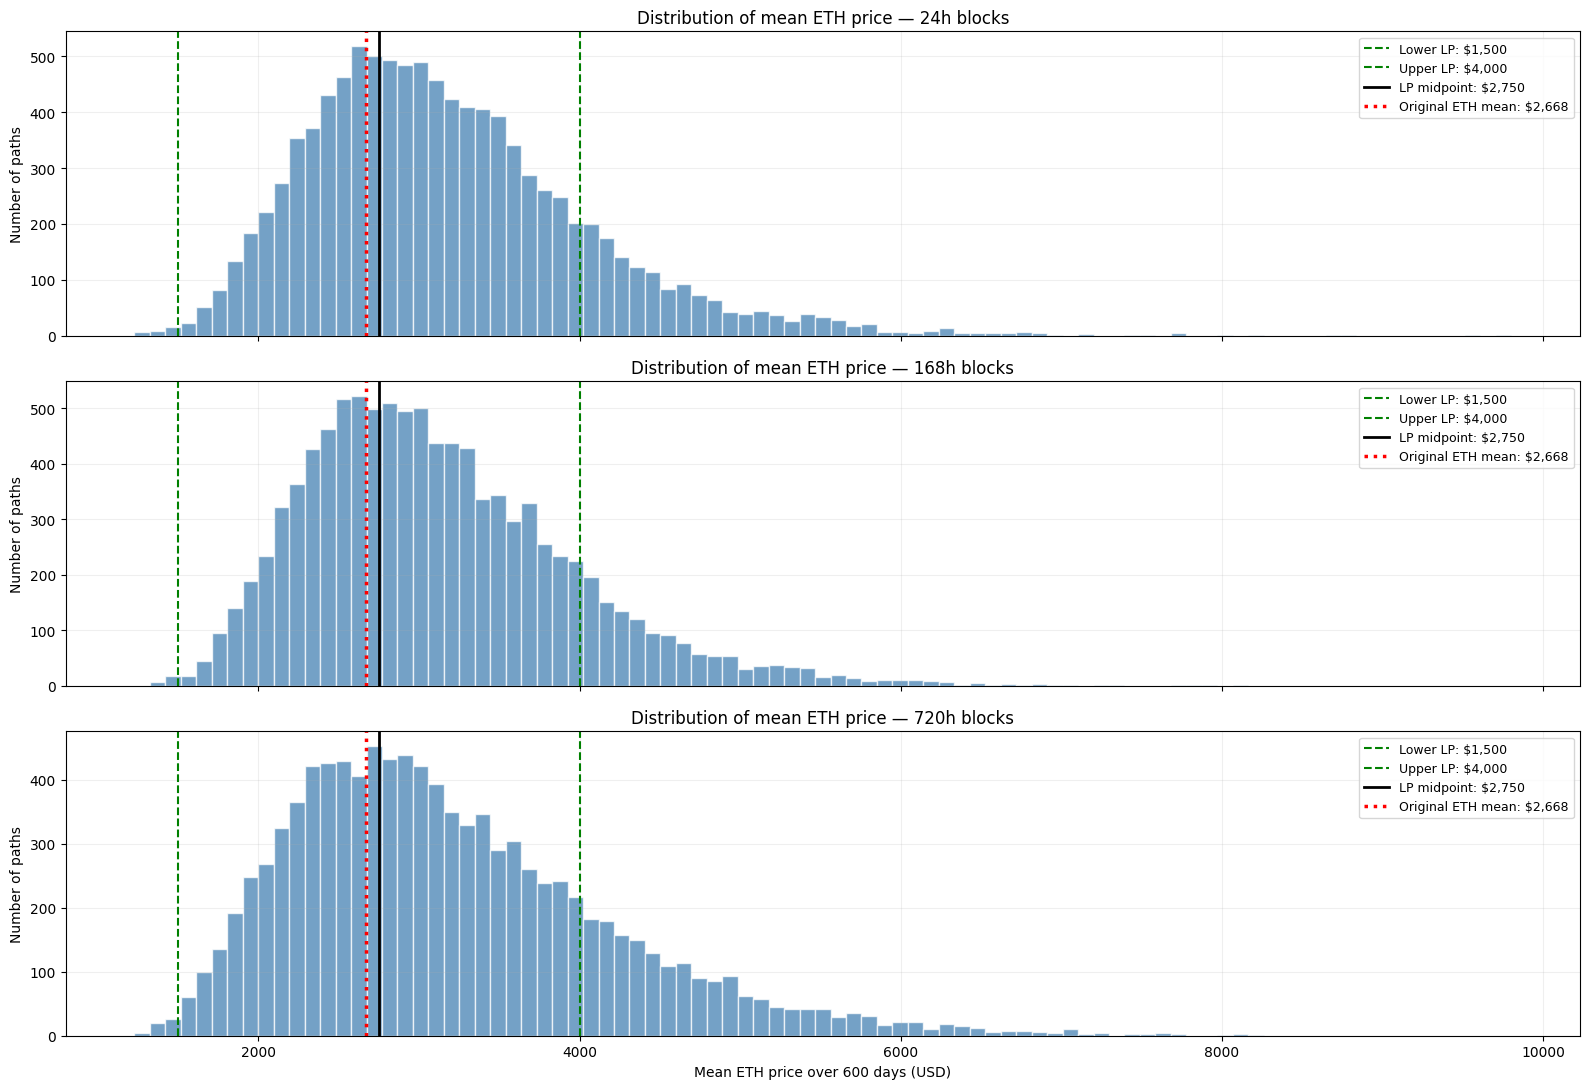

In [6]:

import numpy as np
import matplotlib.pyplot as plt

# ==================================================
# DISTRIBUTION OF MEAN ETH PRICE ACROSS PATHS
# REUSE CACHED STATISTICS
# ==================================================

MIDPOINT = (LOWER + UPPER) / 2

original_mean = float(original_path.mean())

# Reuse already computed means
all_means = np.concatenate([
    path_stats[b]["mean_price"]
    for b in BLOCK_SIZES
])

bins = np.linspace(
    all_means.min(),
    all_means.max(),
    90
)

fig, axes = plt.subplots(
    len(BLOCK_SIZES), 1,
    figsize=(16, 11),
    sharex=True
)

for ax, block_size in zip(axes, BLOCK_SIZES):

    mean_prices = path_stats[block_size]["mean_price"]

    ax.hist(
        mean_prices,
        bins=bins,
        color="steelblue",
        alpha=0.75,
        edgecolor="white"
    )

    ax.axvline(
        LOWER,
        color="green",
        linestyle="--",
        linewidth=1.5,
        label=f"Lower LP: ${LOWER:,.0f}"
    )

    ax.axvline(
        UPPER,
        color="green",
        linestyle="--",
        linewidth=1.5,
        label=f"Upper LP: ${UPPER:,.0f}"
    )

    ax.axvline(
        MIDPOINT,
        color="black",
        linewidth=2,
        label=f"LP midpoint: ${MIDPOINT:,.0f}"
    )

    ax.axvline(
        original_mean,
        color="red",
        linestyle=":",
        linewidth=2.5,
        label=f"Original ETH mean: ${original_mean:,.0f}"
    )

    ax.set_title(
        f"Distribution of mean ETH price — {block_size}h blocks"
    )

    ax.set_ylabel("Number of paths")
    ax.grid(alpha=0.2)
    ax.legend(fontsize=9)

axes[-1].set_xlabel(
    "Mean ETH price over 600 days (USD)"
)

plt.tight_layout()
plt.show()


In [7]:

import numpy as np

# ==================================================
# UNISWAP V3 LP VALUATION AND CAPITAL RISK
# ==================================================

INITIAL_CAPITAL = 10_000.0

sqrt_L = np.sqrt(LOWER)
sqrt_U = np.sqrt(UPPER)


# ==================================================
# 1. UNISWAP V3 TOKEN AMOUNTS
# ==================================================

def lp_amounts(price):

    p = np.asarray(price, dtype=float)

    if np.any(~np.isfinite(p)):
        raise ValueError("Non-finite prices detected")

    if np.any(p <= 0):
        raise ValueError("Prices must be positive")

    sqrt_p = np.sqrt(np.clip(p, LOWER, UPPER))

    eth = 1.0 / sqrt_p - 1.0 / sqrt_U
    usdt = sqrt_p - sqrt_L

    return eth, usdt


# ==================================================
# 2. INITIAL LIQUIDITY
# ==================================================

eth0, usdt0 = lp_amounts(P0)

LIQUIDITY = INITIAL_CAPITAL / (
    P0 * float(eth0) + float(usdt0)
)


# ==================================================
# 3. LP POSITION VALUE
# ==================================================

def lp_value(price):

    p = np.asarray(price, dtype=float)

    eth, usdt = lp_amounts(p)

    return LIQUIDITY * (p * eth + usdt)


# ==================================================
# 4. CAPITAL RISK FOR ALL SIMULATED PATHS
# ==================================================

risk_results = {}

for block_size in BLOCK_SIZES:

    # Reuse cached minimum prices
    min_prices = path_stats[block_size]["full_min"]

    min_capital = lp_value(min_prices)

    loss_pct = (
        1.0 - min_capital / INITIAL_CAPITAL
    ) * 100.0

    risk_results[block_size] = {
        "min_price": min_prices,
        "min_capital": min_capital,
        "loss_pct": loss_pct
    }


# ==================================================
# 5. HISTORICAL CAPITAL RISK
# ==================================================

original_min_price = float(original_path.min())

original_min_capital = float(
    lp_value(original_min_price)
)

historical_loss = (
    1.0 - original_min_capital / INITIAL_CAPITAL
) * 100.0


# ==================================================
# 6. VALIDATION
# ==================================================

assert np.isclose(
    lp_value(P0),
    INITIAL_CAPITAL
)

assert np.isclose(
    original_path[0],
    P0
)

for b in BLOCK_SIZES:

    assert len(risk_results[b]["loss_pct"]) == N_PATHS

    assert np.allclose(
        risk_results[b]["min_capital"],
        lp_value(path_stats[b]["full_min"])
    )

    assert np.all(
        risk_results[b]["min_capital"] <= INITIAL_CAPITAL + 1e-8
    )

print("LP MODEL VALIDATED")
print("-" * 50)

print(f"Entry ETH price:        ${P0:,.2f}")
print(f"Initial capital:        ${INITIAL_CAPITAL:,.2f}")
print(f"LP range:               ${LOWER:,.0f} - ${UPPER:,.0f}")
print(f"Historical min price:   ${original_min_price:,.2f}")
print(f"Historical min capital: ${original_min_capital:,.2f}")
print(f"Historical loss:        {historical_loss:.2f}%")

print("\nSIMULATION RESULTS")

for b in BLOCK_SIZES:

    losses = risk_results[b]["loss_pct"]

    print(
        f"{b:3d}h | "
        f"paths: {len(losses):,} | "
        f"median: {np.median(losses):.2f}% | "
        f"P95: {np.percentile(losses, 95):.2f}%"
    )


LP MODEL VALIDATED
--------------------------------------------------
Entry ETH price:        $3,113.90
Initial capital:        $10,000.00
LP range:               $1,500 - $4,000
Historical min price:   $1,418.80
Historical min capital: $6,006.86
Historical loss:        39.93%

SIMULATION RESULTS
 24h | paths: 10,000 | median: 27.21% | P95: 58.25%
168h | paths: 10,000 | median: 27.96% | P95: 58.02%
720h | paths: 10,000 | median: 31.94% | P95: 63.39%


In [8]:

import numpy as np
import pandas as pd

# ==================================================
# DISTRIBUTION STATISTICS — 600 DAYS
# ==================================================

records = []

for b in BLOCK_SIZES:

    losses = np.asarray(
        risk_results[b]["loss_pct"],
        dtype=float
    )

    records.append({
        "Block": f"{b}h",
        "Mean (%)": np.mean(losses),
        "Median (%)": np.median(losses),
        "Sigma (pp)": np.std(losses, ddof=0),
        "P95 loss (%)": np.percentile(losses, 95),
        "P99 loss (%)": np.percentile(losses, 99),
        "Worst loss (%)": np.max(losses),
        "P(loss > history) %": (
            np.mean(losses > historical_loss) * 100
        )
    })

distribution_stats = pd.DataFrame(records)

print("DISTRIBUTION STATISTICS")
display(distribution_stats.round(2))


DISTRIBUTION STATISTICS


,Block,Mean (%),Median (%),Sigma (pp),P95 loss (%),P99 loss (%),Worst loss (%),P(loss > history) %
0,24h,29.37,27.21,15.81,58.25,68.63,82.81,25.26
1,168h,29.97,27.96,15.65,58.02,67.09,81.05,27.60
2,720h,33.07,31.94,17.59,63.39,71.21,80.88,35.86


In [9]:

import numpy as np
import pandas as pd
from math import erf, sqrt

# ==================================================
# SIGMA COVERAGE & ADVERSE THRESHOLDS
# 168h REFERENCE — 600 DAYS
# ==================================================

# Reuse existing distribution statistics
reference = distribution_stats.loc[
    distribution_stats["Block"] == "168h"
].iloc[0]

REF_MEAN = float(reference["Mean (%)"])
REF_SIGMA = float(reference["Sigma (pp)"])

SIGMA_LEVELS = [1, 2, 3]

# ==================================================
# 1. EMPIRICAL COVERAGE OF SIGMA BANDS
# ==================================================

coverage_records = []

for b in BLOCK_SIZES:

    losses = risk_results[b]["loss_pct"]

    for k in SIGMA_LEVELS:

        lower = REF_MEAN - k * REF_SIGMA
        upper = REF_MEAN + k * REF_SIGMA

        inside = np.mean(
            (losses >= lower) &
            (losses <= upper)
        ) * 100

        above = np.mean(
            losses > upper
        ) * 100

        normal_inside = erf(
            k / sqrt(2)
        ) * 100

        coverage_records.append({
            "Block": f"{b}h",
            "Reference interval": f"+/- {k} sigma",
            "Lower loss (%)": lower,
            "Upper loss (%)": upper,
            "Inside interval (%)": inside,
            "Above upper (%)": above,
            "Normal inside (%)": normal_inside
        })

coverage_stats = pd.DataFrame(coverage_records)

print("EMPIRICAL COVERAGE OF 168h SIGMA BANDS")

display(coverage_stats.round(2))


# ==================================================
# 2. ADVERSE SIGMA THRESHOLDS
# ==================================================

threshold_records = []

losses_168 = risk_results[168]["loss_pct"]

for k in [0, 1, 2, 3]:

    threshold = REF_MEAN + k * REF_SIGMA

    capital_remaining = INITIAL_CAPITAL * (
        1.0 - threshold / 100.0
    )

    probability = np.mean(
        losses_168 >= threshold
    ) * 100

    threshold_records.append({
        "Level": f"+{k} sigma",
        "Loss (%)": threshold,
        "Capital remaining ($)": capital_remaining,
        "P168(loss >= threshold) (%)": probability
    })

threshold_stats = pd.DataFrame(threshold_records)

print("\nADVERSE SIGMA THRESHOLDS — 168h REFERENCE")

display(threshold_stats.round(2))


# ==================================================
# 3. VALIDATION
# ==================================================

assert REF_SIGMA > 0

assert np.all(
    coverage_stats["Inside interval (%)"].between(0, 100)
)

assert np.all(
    coverage_stats["Above upper (%)"].between(0, 100)
)

assert np.all(
    threshold_stats["P168(loss >= threshold) (%)"]
    .between(0, 100)
)

print("\nSIGMA ANALYSIS VALIDATED")
print(f"Reference mean:  {REF_MEAN:.4f}%")
print(f"Reference sigma: {REF_SIGMA:.4f} percentage points")


EMPIRICAL COVERAGE OF 168h SIGMA BANDS


,Block,Reference interval,Lower loss (%),Upper loss (%),Inside interval (%),Above upper (%),Normal inside (%)
0,24h,+/- 1 sigma,14.32,45.62,62.80,17.50,68.27
1,24h,+/- 2 sigma,-1.33,61.27,96.69,3.31,95.45
2,24h,+/- 3 sigma,-16.98,76.92,99.87,0.13,99.73
3,168h,+/- 1 sigma,14.32,45.62,62.77,18.54,68.27
4,168h,+/- 2 sigma,-1.33,61.27,97.06,2.94,95.45
5,168h,+/- 3 sigma,-16.98,76.92,99.97,0.03,99.73
6,720h,+/- 1 sigma,14.32,45.62,56.63,26.58,68.27
7,720h,+/- 2 sigma,-1.33,61.27,93.37,6.63,95.45
8,720h,+/- 3 sigma,-16.98,76.92,99.87,0.13,99.73



ADVERSE SIGMA THRESHOLDS — 168h REFERENCE


,Level,Loss (%),Capital remaining ($),P168(loss >= threshold) (%)
0,+0 sigma,29.97,7003.12,45.82
1,+1 sigma,45.62,5438.14,18.54
2,+2 sigma,61.27,3873.15,2.94
3,+3 sigma,76.92,2308.17,0.03



SIGMA ANALYSIS VALIDATED
Reference mean:  29.9688%
Reference sigma: 15.6498 percentage points


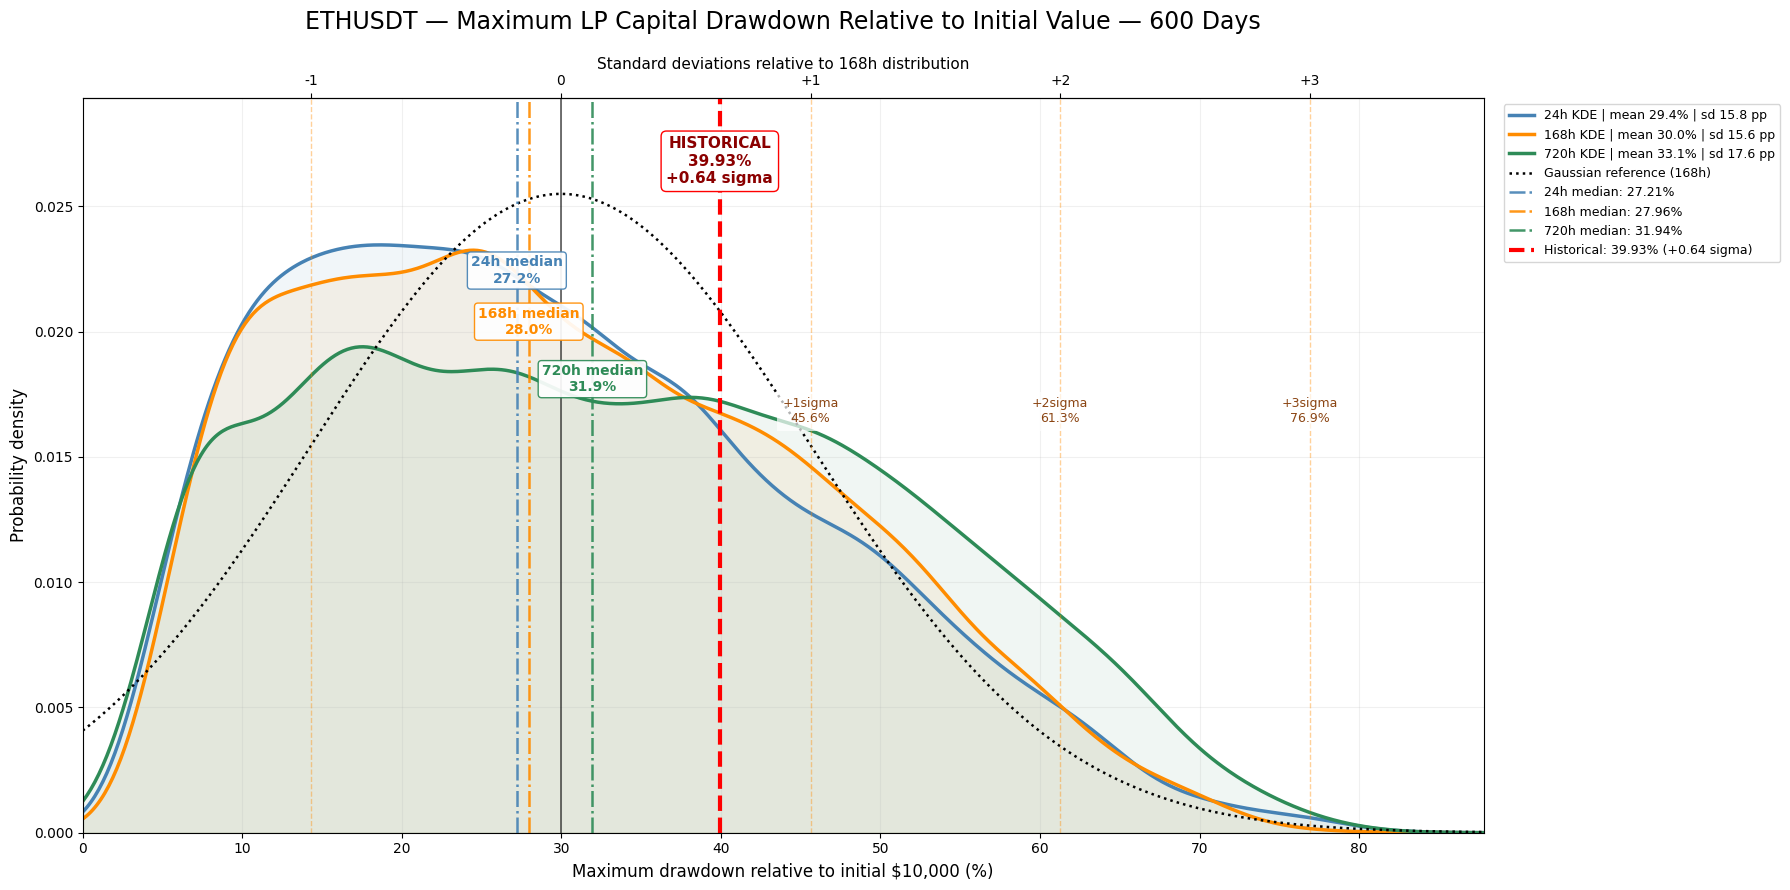

Chart saved: 04_lp_capitalloss_consistent.png
Historical loss: 39.93%
Historical Z-score: +0.637
Monte Carlo paths reused — no new simulations.


In [10]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde, norm

# ==================================================
# FINAL KDE — WORST LP CAPITAL LOSS ACROSS 600 DAYS
# ==================================================

COLORS = {
    24: "steelblue",
    168: "darkorange",
    720: "seagreen"
}

# Use full-precision cached statistics
reference_mean = REF_MEAN
reference_sigma = REF_SIGMA

all_losses = np.concatenate([
    risk_results[b]["loss_pct"]
    for b in BLOCK_SIZES
])

# Loss cannot be negative under the defined metric
x_min = 0.0
x_max = min(
    100.0,
    max(
        all_losses.max(),
        reference_mean + 3 * reference_sigma
    ) + 5.0
)

x = np.linspace(x_min, x_max, 700)

fig, ax = plt.subplots(figsize=(18, 9))

# ==================================================
# 1. EMPIRICAL KDE DISTRIBUTIONS
# ==================================================

medians = {}

for b in BLOCK_SIZES:

    losses = np.asarray(
        risk_results[b]["loss_pct"],
        dtype=float
    )

    mean = np.mean(losses)
    sd = np.std(losses, ddof=0)
    median = np.median(losses)

    medians[b] = median

    kde = gaussian_kde(losses)
    density = kde(x)

    ax.plot(
        x,
        density,
        color=COLORS[b],
        linewidth=2.5,
        label=(
            f"{b}h KDE | mean {mean:.1f}% "
            f"| sd {sd:.1f} pp"
        )
    )

    ax.fill_between(
        x,
        0,
        density,
        color=COLORS[b],
        alpha=0.07
    )


# ==================================================
# 2. GAUSSIAN REFERENCE — 168h
# ==================================================

gaussian = norm.pdf(
    x,
    loc=reference_mean,
    scale=reference_sigma
)

ax.plot(
    x,
    gaussian,
    color="black",
    linestyle=":",
    linewidth=1.8,
    label="Gaussian reference (168h)"
)


# ==================================================
# 3. SIGMA REFERENCE LINES
# ==================================================

for k in [-2, -1, 0, 1, 2, 3]:

    level = reference_mean + k * reference_sigma

    if level < x_min or level > x_max:
        continue

    if k == 0:
        ax.axvline(
            level,
            color="black",
            linewidth=1.2,
            alpha=0.65
        )
    else:
        ax.axvline(
            level,
            color="darkorange",
            linestyle="--",
            linewidth=1,
            alpha=0.40
        )


# ==================================================
# 4. MEDIAN LOSS LINES
# ==================================================

label_heights = {
    24: 0.88,
    168: 0.80,
    720: 0.71
}

for b in BLOCK_SIZES:

    median = medians[b]

    ax.axvline(
        median,
        color=COLORS[b],
        linestyle="-.",
        linewidth=1.8,
        alpha=0.9,
        label=f"{b}h median: {median:.2f}%"
    )


# ==================================================
# 5. HISTORICAL LOSS
# ==================================================

historical_z = (
    historical_loss - reference_mean
) / reference_sigma

ax.axvline(
    historical_loss,
    color="red",
    linestyle="--",
    linewidth=3,
    label=(
        f"Historical: {historical_loss:.2f}% "
        f"({historical_z:+.2f} sigma)"
    )
)


# ==================================================
# 6. AXES AND LABELS
# ==================================================

ax.set_xlim(x_min, x_max)

ax.set_title(
    "ETHUSDT — Maximum LP Capital Drawdown Relative to Initial Value — 600 Days",
    fontsize=17,
    pad=20
)

ax.set_xlabel(
    "Maximum drawdown relative to initial $10,000 (%)",
    fontsize=12
)

ax.set_ylabel(
    "Probability density",
    fontsize=12
)

ax.grid(
    True,
    alpha=0.18
)

# Secondary X-axis in reference sigma units
def loss_to_sigma(loss):
    return (loss - reference_mean) / reference_sigma

def sigma_to_loss(sigma):
    return reference_mean + sigma * reference_sigma

secax = ax.secondary_xaxis(
    "top",
    functions=(loss_to_sigma, sigma_to_loss)
)

sigma_ticks = [-1, 0, 1, 2, 3]

secax.set_xticks(sigma_ticks)

secax.set_xticklabels([
    f"{k:+d}" if k != 0 else "0"
    for k in sigma_ticks
])

secax.set_xlabel(
    "Standard deviations relative to 168h distribution",
    fontsize=11
)


# ==================================================
# 7. ANNOTATIONS
# ==================================================

ymax = max(
    np.max(gaussian),
    *[
        gaussian_kde(
            risk_results[b]["loss_pct"]
        )(x).max()
        for b in BLOCK_SIZES
    ]
)

ax.set_ylim(0, ymax * 1.15)

for b in BLOCK_SIZES:

    median = medians[b]

    ax.text(
        median,
        ymax * label_heights[b],
        f"{b}h median\n{median:.1f}%",
        color=COLORS[b],
        fontsize=10,
        fontweight="bold",
        ha="center",
        va="center",
        bbox=dict(
            facecolor="white",
            edgecolor=COLORS[b],
            alpha=0.92,
            boxstyle="round,pad=0.25"
        )
    )

ax.text(
    historical_loss,
    ymax * 1.09,
    (
        f"HISTORICAL\n"
        f"{historical_loss:.2f}%\n"
        f"{historical_z:+.2f} sigma"
    ),
    color="darkred",
    fontsize=11,
    fontweight="bold",
    ha="center",
    va="top",
    bbox=dict(
        facecolor="white",
        edgecolor="red",
        boxstyle="round,pad=0.35"
    )
)

# Positive reference sigma labels
for k in [1, 2, 3]:

    level = reference_mean + k * reference_sigma

    if level <= x_max:
        ax.text(
            level,
            ymax * 0.66,
            f"+{k}sigma\n{level:.1f}%",
            color="saddlebrown",
            fontsize=9,
            ha="center",
            va="center",
            bbox=dict(
                facecolor="white",
                edgecolor="none",
                alpha=0.7
            )
        )


# ==================================================
# 8. LEGEND AND SAVE
# ==================================================

ax.legend(
    loc="upper left",
    bbox_to_anchor=(1.01, 1),
    fontsize=9
)

plt.tight_layout()

OUTPUT_FILE = "04_lp_capitalloss_consistent.png"

fig.savefig(
    OUTPUT_FILE,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print(f"Chart saved: {OUTPUT_FILE}")
print(f"Historical loss: {historical_loss:.2f}%")
print(f"Historical Z-score: {historical_z:+.3f}")
print("Monte Carlo paths reused — no new simulations.")


In [11]:
for b in BLOCK_SIZES:
    losses = risk_results[b]["loss_pct"]
    count = np.count_nonzero(losses >= 50)

    print(
        f"{b}h: {count:,} / {len(losses):,} "
        f"= {count / len(losses) * 100:.2f}%"
    )

24h: 1,210 / 10,000 = 12.10%
168h: 1,263 / 10,000 = 12.63%
720h: 1,981 / 10,000 = 19.81%
